# Lending Game — Part 12: Pricing the Round 2 applications and writing the submission

The last step of Round 2, as in Part 8:

1. **Predict**: our default probability for each of the 100,000 Round 2 applicants (ids 100,001 to
   200,000). Part 11 refitted our model (spline logistic on public variables + `signal3`) on the
   200,000 loans now known (past loans + Round 1) and saved `p_own_200k` in
   `data/predictions/applications_round2_own.csv`.
2. **Price**: apply the rule chosen in Part 11, **R4-step|R8**, saved in
   `data/pricing/final_rule_round2.json` and rebuilt with `r2.load_round2_rule()`.
3. **Submit**: write `submissions/Lender3_Round2_submission.csv` (columns `id` and `rate`, decimal, at
   most 1, empty when we make no offer) and check it.
4. **Preview**: what the rule should earn on these applicants if the competitors behave as in Round 1,
   or adapt as in Part 11's stresses.

The functions are in `src/submission_round_2.py`.

## 1. Inputs

In [1]:
import sys
sys.path.append("..")  # make src/ importable from analysis/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import FIGURES_DIR, DATA_PREDICTIONS
from src.pricing_rules import be
from src import round_2_rule as r2
from src import submission_round_2 as s2
from src import model_plots as mp

mp.set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)


def save(fig, name):
    # Save a figure for the Part 12 report.
    fig.savefig(FIGURES_DIR / name, dpi=150, bbox_inches="tight")


apps = s2.load_round2_applications()        # raises if ids or predictions do not match
round1 = pd.read_csv(DATA_PREDICTIONS / "applications_own.csv", index_col="id")

print(f"Round 2 applicants: {len(apps):,}, ids {apps.index.min():,} to {apps.index.max():,}, "
      f"all with a prediction")
pct = [.1, .5, .9, .99]
compare = pd.DataFrame({"Round 2, p_own_200k (priced)": apps["p_own_200k"].describe(percentiles=pct),
                        "Round 2, p_own_100k": apps["p_own_100k"].describe(percentiles=pct),
                        "Round 1 applicants, p_own": round1["p_own"].describe(percentiles=pct)}).drop("count")
display(compare.style.format("{:.2%}"))

Round 2 applicants: 100,000, ids 100,001 to 200,000, all with a prediction


,"Round 2, p_own_200k (priced)","Round 2, p_own_100k","Round 1 applicants, p_own"
mean,9.93%,9.93%,9.96%
std,7.54%,7.74%,7.74%
min,0.02%,0.01%,0.01%
10%,1.31%,1.28%,1.29%
50%,8.75%,8.62%,8.67%
90%,20.31%,20.46%,20.45%
99%,32.47%,33.44%,33.69%
max,45.46%,48.09%,50.20%


* **100,000 applicants, ids 100,001 to 200,000**, each with a prediction from both models.
* **The Round 2 applicants look like the Round 1 applicants**: same mean predicted risk (9.93% vs
  9.96%), same median and 90th percentile. The rule tuned on Round 1 applies without adjustment.
* The 200k model is slightly less spread at the top (99th percentile 32.5% vs 33.4%, maximum 45.5%
  vs 48.1%): Part 11 found the 100k model over-predicted above 30% risk, and the refit corrects part of
  it.

## 2. The rule

In [2]:
rule, spec = s2.load_rule()
hyb = spec["hybrid"]
print(f"rule: {rule.name}; switch at p_own = {hyb['p_switch']:.2%}, quote {hyb['quote']:.0%}, "
      f"rate floor {spec['poly']['floor']:.1%}")
display(s2.rule_table(spec).style.format({"p_own from": "{:.2%}", "p_own to": "{:.2%}"}))

rule: R4-step|R8; switch at p_own = 8.69%, quote 82%, rate floor 0.5%


,p_own from,p_own to,rate
0,0.00%,1.22%,be + 3.00 pts
1,1.22%,2.75%,be + 2.75 pts
2,2.75%,4.47%,be + 2.25 pts
3,4.47%,6.45%,be + 3.25 pts
4,6.45%,8.69%,be + 3.25 pts
5,8.69%,45.05%,82% flat
6,45.05%,100.00%,no offer


**R4-step|R8**, chosen in Part 11 (smallest max regret over 36 held-out scenarios):

* **below $p_{own} = 8.69\%$**: break-even $p/(1-p)$ plus a step margin of 2.25–3.25 points;
* **from 8.69%**: a flat **82%** quote, just under the rival high quotes of Round 1 (91.99%, 97.89%)
  and the 85% they might cut to;
* **no offer from $p_{own} = 0.82/1.82 = 45.05\%$**, where 82% is below our own break-even and the
  expected profit $(1-p)\,0.82 - p$ would be negative. This replaces the general "no offer when
  $p \ge 50\%$" rule.

## 3. Pricing the 100,000 applicants

In [3]:
rates = s2.price(apps, rule)                 # NaN = no offer
reason = s2.no_offer_reasons(apps, rates, spec)
display(reason.value_counts().to_frame("applicants"))

edges = [0.0] + [e for e in spec["poly"]["edges"] if e <= hyb["p_switch"] + 1e-12] + [0.15, 0.30,
         hyb["quote"] / (1 + hyb["quote"]), 1.0]
labels = [f"{100 * a:.1f}-{100 * b:.1f}%" for a, b in zip(edges[:-2], edges[1:-1])] + [f">= {100 * edges[-2]:.2f}%"]
by_band = s2.offers_by_band(apps, rates, edges, labels)
display(by_band.style.format({"applicants": "{:,}", "offers": "{:,}", "mean_p": "{:.2%}",
                              "mean_rate": "{:.2%}", "min_rate": "{:.2%}", "max_rate": "{:.2%}",
                              "mean_margin": "{:.2%}"}, na_rep="-"))
print(f"no offer for p_own >= {hyb['quote'] / (1 + hyb['quote']):.2%}: ids",
      list(apps.index[rates.isna()]))

,applicants
offer: 82% quote,50251
offer: break-even + margin,49739
no offer: quote below our break-even,10


,applicants,mean_p,offers,mean_rate,min_rate,max_rate,mean_margin
band,,,,,,,
0.0-1.2%,"9,344",0.60%,"9,344",3.60%,3.02%,4.24%,3.00%
1.2-2.8%,"10,086",1.97%,"10,086",4.76%,3.99%,5.58%,2.75%
2.8-4.5%,"9,943",3.59%,"9,943",5.98%,5.08%,6.93%,2.25%
4.5-6.4%,"10,050",5.44%,"10,050",9.00%,7.93%,10.14%,3.25%
6.4-8.7%,"10,316",7.55%,"10,316",11.42%,10.14%,12.77%,3.25%
8.7-15.0%,"28,850",11.93%,"28,850",82.00%,82.00%,82.00%,68.41%
15.0-30.0%,"19,863",20.24%,"19,863",82.00%,82.00%,82.00%,56.34%
30.0-45.1%,"1,538",34.51%,"1,538",82.00%,82.00%,82.00%,28.83%
>= 45.05%,10,45.25%,0,-,-,-,-


no offer for p_own >= 45.05%: ids [117571, 126532, 140346, 145592, 158080, 176844, 182739, 188208, 192515, 199333]


* **99,990 offers, 10 no-offers.** The 10 applicants without an offer all have $p_{own}$ above
  45.05% (the highest is 45.5%), where the 82% quote would lose money in expectation.
* **Two halves, as designed:**
  * **49,739 safer applicants** ($p_{own} < 8.69\%$) get break-even + 2.25–3.25 points: 3.0–4.2% for
    the safest tenth, up to 12.8% just below the switch. This is the contested market, where we expect
    to win loans at a thin margin.
  * **50,251 riskier applicants** all get 82%. We expect to win them only where no competitor offers,
    or where the competitors only quote high; elsewhere the quote rarely wins.
* The 0.5% floor never binds: the lowest rate is 3.02%.

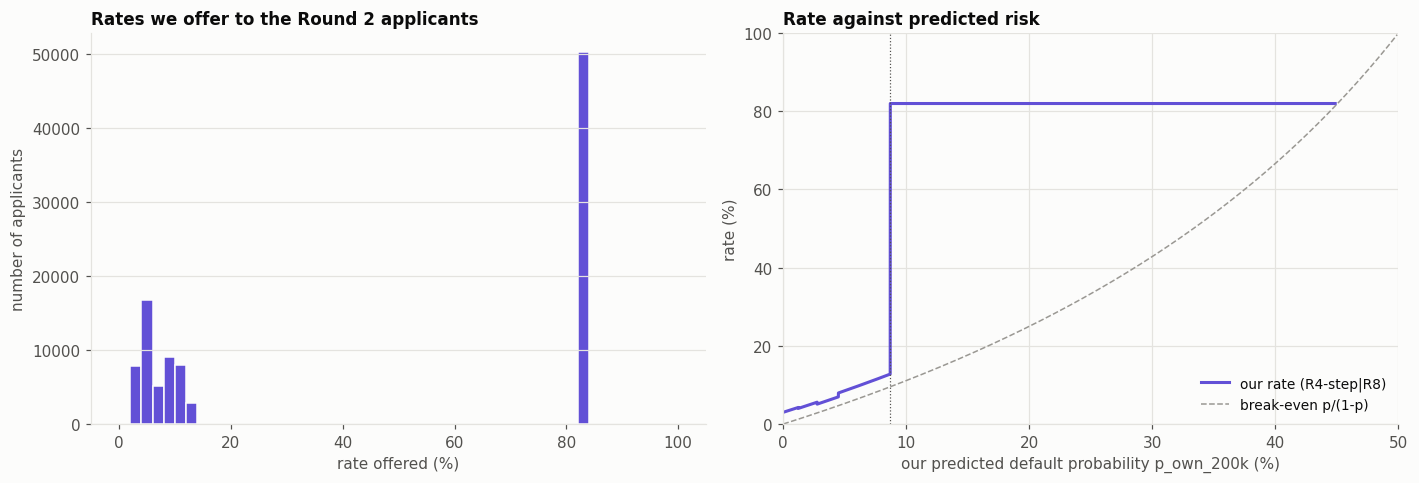

In [4]:
p = apps["p_own"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.hist(100 * rates.dropna(), bins=np.arange(0, 102, 2), color=mp.SINGLE_COLOR,
        edgecolor=mp.SURFACE, linewidth=1)
ax.set_xlabel("rate offered (%)")
ax.set_ylabel("number of applicants")
ax.set_title("Rates we offer to the Round 2 applicants")
ax.grid(axis="x", visible=False)

ax = axes[1]
order = np.argsort(p.to_numpy())
ax.plot(100 * p.to_numpy()[order], 100 * rates.to_numpy()[order], color=mp.SINGLE_COLOR,
        label=f"our rate ({rule.name})")
grid = np.linspace(0, 0.499, 300)
ax.plot(100 * grid, 100 * be(grid), color=mp.REFERENCE, lw=1, ls="--", label="break-even p/(1-p)")
ax.axvline(100 * hyb["p_switch"], color=mp.INK_SECONDARY, lw=0.8, ls=":")
ax.set_xlim(0, 50)
ax.set_ylim(0, 100)
ax.set_xlabel("our predicted default probability p_own_200k (%)")
ax.set_ylabel("rate (%)")
ax.set_title("Rate against predicted risk")
ax.legend()
fig.tight_layout()
save(fig, "fig32_round2_rates.png")
plt.show()

The rate curve sits 2–3 points above break-even up to the switch, then jumps to 82% (right). Hence the two
groups in the histogram (left): half of the offers between 3% and 13%, the other half at exactly 82%.

## 4. Does the choice of model matter?

In [5]:
display(s2.compare_models(apps, rule, hyb["p_switch"]).to_frame("value"))

,value
correlation of p_own,0.998769
"mean p_own, 100k model",0.099345
"mean p_own, 200k model",0.099330
"above switch, 100k model",49724.000000
"above switch, 200k model",50261.000000
change side of the switch,1137.000000
same rate (both offer),49380.000000
mean |rate change| where both offer,0.008806


**The model choice barely matters, as Part 11 found.**

* The two predictions correlate at 0.9988, with the same mean.
* **1,137 applicants (1.1%) change side of the switch**. With the 200k model, 537 more applicants get
  the 82% quote.
* Where both models give an offer, the rate changes by 0.9 points on average. Almost all of that comes
  from the applicants that switch side. On the others, the rate moves by a few hundredths of a point.

## 5. Writing and checking the submission file

In [6]:
submission = s2.make_submission(rates)
summary = s2.check_submission(submission, apps.index)       # course format; raises on any problem
counts = s2.check_rule(apps, rates, spec)                   # every rate is the saved rule's
path = s2.write_submission(submission, s2.SUBMISSION_FILE)
print(f"written {path.relative_to(path.parents[1])}")
display(pd.Series({"applications": f"{summary['applications']:,}", "offers": f"{summary['offers']:,}",
                   "  of which break-even + margin": f"{counts['margin offers']:,}",
                   "  of which the flat quote": f"{counts['quote offers']:,}",
                   "no offer (empty rate)": f"{summary['no offer']:,}",
                   "lowest rate": f"{summary['min rate']:.2%}", "median rate": f"{summary['median rate']:.2%}",
                   "highest rate": f"{summary['max rate']:.2%}"}).to_frame("value"))

# Read the file back exactly as it will be sent, and check it again.
reread = pd.read_csv(path)
s2.check_submission(reread, apps.index)
back = reread.set_index("id")["rate"]
s2.check_rule(apps, back, spec, tol=5e-7)                 # 6 decimals in the file
print("file re-read: same ids:", reread["id"].tolist() == submission["id"].tolist(),
      "| same rates (6 decimals):", np.allclose(reread["rate"], submission["rate"], atol=1e-6, equal_nan=True),
      "| empty cells:", int(reread["rate"].isna().sum()))
print()
print(open(path).read()[:200])

written submissions/Lender3_Round2_submission.csv


,value
applications,"100,000"
offers,"99,990"
of which break-even + margin,"49,739"
of which the flat quote,"50,251"
no offer (empty rate),10
lowest rate,3.02%
median rate,82.00%
highest rate,82.00%


file re-read: same ids: True | same rates (6 decimals): True | empty cells: 10

id,rate
100001,0.820000
100002,0.105526
100003,0.086008
100004,0.030976
100005,0.063067
100006,0.049168
100007,0.820000
100008,0.110129
100009,0.063999
100010,0.080508
100011,0.083494
100012,0.820000



* **The file passes every course rule**: 100,000 rows, ids 100,001 to 200,000 once each, columns `id`
  and `rate`, every rate a decimal in (0, 1], empty when we make no offer.
* **Every rate is the one the saved rule prescribes.** `check_rule` recomputes the rates from the
  JSON alone, without the Part 11 code, on the table and on the file read back.
* **No offer is below our break-even**: every loan we offer has a positive expected profit under
  $p_{own}$.

## 6. What should it earn?

In [7]:
base = r2.make_poly_rule({k: np.asarray(v) if k != "degree" else v for k, v in spec["poly"].items()
                          if k != "floor"})
rules = {rule.name: rule, "R4-step (no quote)": base, "R4 (Round 1)": r2.round1_r4()}
forecast, loans = s2.forecast_profit(apps, rules, seeds=range(10))
display(forecast.style.format(lambda v: f"{v / 1e6:+.1f}M"))
display(loans.style.format("{:,.0f}"))

,empirical (Round 1 repeats),never-offer teams offer,high quotes at 85%,no-offers & high quotes -50%,curves -1 pt,pool gone (-100%),sd
R4-step|R8,+82.3M,+26.0M,+82.3M,+25.1M,+80.1M,+3.9M,+1.0M
R4-step (no quote),+32.2M,+17.4M,+32.2M,+17.2M,+29.7M,+6.3M,+1.1M
R4 (Round 1),+34.3M,+18.4M,+34.3M,+17.7M,+32.4M,+5.6M,+1.1M


,empirical (Round 1 repeats),never-offer teams offer,high quotes at 85%,no-offers & high quotes -50%,curves -1 pt,pool gone (-100%)
R4-step|R8,"40,305","23,510","40,305","24,554","34,196","17,035"
R4-step (no quote),"51,624","34,701","51,582","34,420","44,960","21,040"
R4 (Round 1),"55,704","38,464","55,655","38,500","49,737","24,957"


A preview, not a forecast of the result. Defaults are drawn from $p_{own}$ (10 draws). Competitor
offers are resampled from the Round 1 market given risk and default (Part 10's empirical scenario).
Profit is averaged over the borrower types. The competitors are Round 1's teams, adapted only through
the stress knobs.

* **If Round 1 repeats, the rule should make about €82M**, against €34M for the Round 1 R4. That is the
  same figure as its exact Round 1 counterfactual in Part 11 (€82.3M), so the Round 2 applicants
  change nothing.
* **High quotes cut to 85% cost nothing**, since 82% is already below them. **Cheaper curves** (−1 pt)
  cost about €2M.
* **If the never-offer teams start lending, or half the uncontested pool disappears**, profit falls to
  €25–26M. That is still €8M more than R4.
* **If the uncontested pool disappears entirely**, it makes €3.9M, against €5.6–6.3M for the rules
  without the quote. That is the insurance premium Part 11 accepted.
* **One draw of the defaults moves profit by about ±€1M** (standard deviation over draws in the
  empirical scenario).

## 7. Summary

* **Submission file:** `submissions/Lender3_Round2_submission.csv`, with 100,000 rows (ids 100,001 to
  200,000). It contains 99,990 offers and 10 empty rates, and passes every format check and the rule
  check.
* **Pipeline:**
  * Part 11's model, refitted on 200k loans, predicts $p_{own}$.
  * Part 11's rule **R4-step|R8** prices it: break-even + 2.25–3.25 points below 8.69% risk, a flat
    82% above, and no offer from 45.05%.
* **Expected profit:** about €82M if the competitors behave as in Round 1, €25M if they close half the
  uncontested pool, and €4M if they close all of it.